<a href="https://colab.research.google.com/github/aeas5/federated-machine-learning-IMDB/blob/main/Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preparation for Federated Learning — Topic A: IMDB Sentiment Analysis
**Federated Machine Learning Programmierpraktikum  SBE TU Berlin**

**Scenario.** Several streaming platforms want to learn together to classify movie reviews as **positive** or **negative**, while each platform keeps its own reviews in-house. IMDB has no platform column, so we **simulate** the platforms by splitting the data into client datasets.

**Today's scope.** We *prepare data*. We do **not** train a model and we do **not** run a federated server.

**Workflow:** `Load → Explore → Clean → Check duplicates → Tokenize → Partition (3 scenarios) → Local split → Export → Verify`

| # | Your task | Section |
|---|---|---|
| TODO 1 | Detect duplicate reviews | 3 |
| TODO 2 | Measure token lengths on a *random* sample and choose `MAX_LENGTH` | 4 |
| TODO 3 | Non-IID partitioning with a Dirichlet distribution | 6 |
| TODO 4 | Quantity-skew partitioning | 6 |
| TODO 5 | Stratified local train/validation split per client | 7 |
| TODO 6 | Reflection questions (README) | 10 |

**Quick start (Google Colab).** Run the notebook top to bottom with `FAST_MODE=True` (a few minutes). When every CHECK passes, set `FAST_MODE=False`, run everything again and download the ZIP at the end.

## 0. Environment and configuration
**Why.** Every client must apply *the same* preprocessing rules , the same cleaning, the same tokenizer and the same `MAX_LENGTH` ,otherwise the models of different clients do not share compatible inputs and their parameters cannot be averaged.

All settings live in one cell. Your exported data must be reproducible from these values alone.

In [ ]:
%pip -q install "datasets>=3,<5" "transformers>=4.40,<6" "scikit-learn>=1.4,<2" "matplotlib>=3.7,<4"

In [ ]:
import html
import json
import re
import shutil
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

# ---- configuration: all experiment settings in one place --------------------
SEED = 42
NUM_CLIENTS = 4            # simulated streaming platforms
ALPHA = 0.30               # Dirichlet concentration for label skew (smaller = stronger skew)
QUANTITY_BETA = 0.50       # Dirichlet concentration for client sizes (smaller = more unequal)
MIN_CLIENT_SAMPLES = 50    # every client needs enough data for a local split
MIN_EACH_LABEL = 5         # ... and a few examples of each class
VAL_FRACTION = 0.20        # local validation share per client
MAX_LENGTH = 128           # token limit; you will revisit this in TODO 2
TOKENIZER_NAME = "distilbert-base-uncased"
SCENARIOS = ["iid", "non_iid", "quantity_skew"]
FAST_MODE = True           # first run: small, fast preview; final export: False
OUTPUT_DIR = Path("imdb_fl_artifacts")

assert NUM_CLIENTS >= 2 and 0 < VAL_FRACTION < 0.5
print("Configuration loaded. FAST_MODE =", FAST_MODE)

Configuration loaded. FAST_MODE = True


## 1. Load the IMDB dataset
The supervised part of IMDB has **25,000 training** and **25,000 test** reviews (plus a 50,000-row `unsupervised` split we do not need). Columns: `text` (the review) and `label` (`0 = negative`, `1 = positive`). Train and test are about **disjoint sets of movies**.



Dataset card: https://huggingface.co/datasets/stanfordnlp/imdb

In [ ]:
train_raw = load_dataset("stanfordnlp/imdb", split="train")
test_raw = load_dataset("stanfordnlp/imdb", split="test")

print("Train rows:", len(train_raw), "| Test rows:", len(test_raw))
print("Columns:", train_raw.column_names)
print("Label names:", train_raw.features["label"].names)
assert len(train_raw) == 25_000 and len(test_raw) == 25_000
assert set(train_raw.column_names) >= {"text", "label"}

# label arrays, computed once and reused everywhere
labels_all = np.asarray(list(train_raw["label"]), dtype=np.int64)
test_labels_all = np.asarray(list(test_raw["label"]), dtype=np.int64)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train rows: 25000 | Test rows: 25000
Columns: ['text', 'label']
Label names: ['neg', 'pos']


## 2. Explore before changing anything
Are labels balanced? How long are reviews? What does a review look like? *And in which order are the rows stored?*



Example review (first 400 characters):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student name


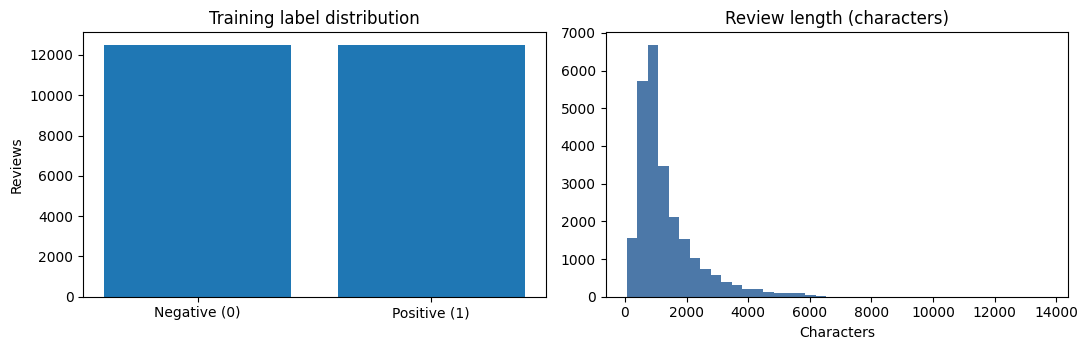

In [ ]:
print("Example review (first 400 characters):")
print(train_raw[0]["text"][:400])

char_lengths = np.array([len(t) for t in train_raw["text"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(["Negative (0)", "Positive (1)"], np.bincount(labels_all, minlength=2))
axes[0].set_title("Training label distribution")
axes[0].set_ylabel("Reviews")
axes[1].hist(char_lengths, bins=40, color="#4c78a8")
axes[1].set_title("Review length (characters)")
axes[1].set_xlabel("Characters")
plt.tight_layout()
plt.show()

In [ ]:
# In which order are the rows stored?
print("First 10 labels:", labels_all[:10].tolist())
print("Last 10 labels: ", labels_all[-10:].tolist())
first_positive = int(np.argmax(labels_all == 1))
print("First positive review at row:", first_positive)

First 10 labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Last 10 labels:  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
First positive review at row: 12500


## 3. Minimal, consistent text cleaning
We remove **formatting artifacts** (HTML line breaks, HTML entities, repeated whitespace) and nothing else. We deliberately keep negations, stop words and punctuation: removing *"not"* turns *"not good"* into *"good"*.

In [ ]:
def clean_review(text: str) -> str:
    # Keep every sentiment-bearing word; normalise HTML and whitespace only.
    text = html.unescape(text)
    text = re.sub(r"(?i)<br\s*/?>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

example_text = "The movie was NOT bad!<br /><br />I enjoyed it &amp; laughed."
print("Before:", example_text)
print("After: ", clean_review(example_text))
assert "NOT bad" in clean_review(example_text)
assert "<br" not in clean_review(example_text)

Before: The movie was NOT bad!<br /><br />I enjoyed it &amp; laughed.
After:  The movie was NOT bad! I enjoyed it & laughed.


### TODO 1 — Duplicate reviews
Public datasets often contain the same review more than once. A review that appears in **both** train and test is a quiet form of leakage: the model may have seen a "test" example during training.

Complete `duplicate_stats(train_texts, test_texts)`. It receives two lists of **cleaned** texts and returns a tuple:
1. `extra_copies_in_train` — how many training rows are *repeats* of an earlier training row (a text that occurs 3 times counts as 2 extra copies);
2. `shared_with_test` — how many **distinct** texts occur in both lists.

*Hint:* `len(...)`, `set(...)` and set intersection are enough.

In [ ]:
def duplicate_stats(train_texts, test_texts):
    # TODO 1: return (extra_copies_in_train, shared_with_test)
    # YOUR CODE HERE
    train_unique = set(train_texts)
    test_unique = set(test_texts)

    extra_copies_in_train = len(train_texts) - len(train_unique)
    shared_with_test = len(train_unique & test_unique)

    return (extra_copies_in_train, shared_with_test)

In [ ]:
# CHECK 1 — do not edit
assert duplicate_stats(["a", "b", "a", "c", "a"], ["c", "d", "a"]) == (2, 2)
assert duplicate_stats(["x", "y"], ["z"]) == (0, 0)
clean_train_texts = [clean_review(t) for t in train_raw["text"]]
clean_test_texts = [clean_review(t) for t in test_raw["text"]]
DUPLICATES = dict(zip(["extra_copies_in_train", "shared_with_test"],
                      duplicate_stats(clean_train_texts, clean_test_texts)))
print("Duplicate statistics on IMDB:", DUPLICATES)
print("PASS")

Duplicate statistics on IMDB: {'extra_copies_in_train': 98, 'shared_with_test': 123}
PASS


## 4. Tokenization and a fixed input length
A tokenizer maps text to tokens and tokens to **integer IDs** from one fixed vocabulary. `attention_mask` marks real tokens (`1`) versus padding (`0`). Every input is padded or truncated to `MAX_LENGTH` tokens.


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=True)
encoded = tokenizer(clean_review(train_raw[0]["text"]), truncation=True,
                    padding="max_length", max_length=MAX_LENGTH)
print("First 15 token IDs:     ", encoded["input_ids"][:15])
print("First 15 attention mask:", encoded["attention_mask"][:15])
print("Length:", len(encoded["input_ids"]), "| real tokens:", sum(encoded["attention_mask"]))
assert len(encoded["input_ids"]) == MAX_LENGTH

### TODO 2 — How long are reviews in tokens?
Characters are not tokens. To choose `MAX_LENGTH` we need the **token** length distribution — measured on a **random** sample of the training set (remember Section 2: the first rows are not representative!).

Complete `sample_token_lengths(dataset, labels, n, seed)`:
1. draw `n` **distinct random** row indices with `np.random.default_rng(seed)`;
2. clean those reviews and tokenize them **without truncation** (`truncation=False`);
3. return `(indices, lengths)` as two NumPy arrays.

In [ ]:
def sample_token_lengths(dataset, labels, n, seed):
    # TODO 2: return (indices, lengths) for n distinct random rows
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(dataset), size=n, replace=False).astype(np.int64)
    texts = [clean_review(dataset[int(i)]["text"]) for i in indices]
    encoded = tokenizer(texts, truncation=False)
    lengths = np.array([len(ids) for ids in encoded["input_ids"]], dtype=np.int64)

    return indices, lengths

In [ ]:
# CHECK 2 — do not edit
probe_idx, probe_len = sample_token_lengths(train_raw, labels_all, n=1000, seed=SEED)
probe_idx2, _ = sample_token_lengths(train_raw, labels_all, n=1000, seed=SEED)
assert len(probe_idx) == len(probe_len) == 1000, "Return 1000 indices and 1000 lengths"
assert len(np.unique(probe_idx)) == 1000, "Indices must be distinct"
assert np.array_equal(probe_idx, probe_idx2), "Same seed must give the same sample"
share_pos = labels_all[probe_idx].mean()
assert 0.4 < share_pos < 0.6, f"Sample is not random: {share_pos:.0%} positive"
TOKEN_STATS = {
    "median": int(np.median(probe_len)),
    "p90": int(np.percentile(probe_len, 90)),
    "share_over_128": float(np.mean(probe_len > 128)),
    "share_over_256": float(np.mean(probe_len > 256)),
    "share_over_512": float(np.mean(probe_len > 512)),
}
print(TOKEN_STATS)
plt.figure(figsize=(6, 3.2))
plt.hist(probe_len, bins=40, color="#4c78a8")
for limit in (128, 256, 512):
    plt.axvline(limit, color="#c40d1e", linestyle="--", linewidth=1)
plt.title("Tokens per review (random sample of 1,000)")
plt.xlabel("Tokens")
plt.tight_layout()
plt.show()
print("PASS")

NameError: name 'sample_token_lengths' is not defined

**Choose `MAX_LENGTH`.** Look at the statistics above. A longer limit keeps more of each review but costs memory, storage and training time on every client. Set your value in the next cell and justify it in one sentence (README, TODO 6).

In [ ]:
MAX_LENGTH = 128   # TODO 2b: keep or change based on the statistics above
print("MAX_LENGTH =", MAX_LENGTH)

## 5. Working pool (optional fast preview)
With `FAST_MODE=True` we take a **stratified** subset of the training split (6,000 reviews) and of the test split (1,000 reviews) so that the lab runs quickly. With `FAST_MODE=False` we use all 25,000 + 25,000. No row ever moves between train and test.

*Bookkeeping:* partition functions work with **positions** `0 … len(pool)-1`; `train_pool_indices[position]` gives the original IMDB row.

In [ ]:
def choose_indices(labels, n_keep, seed):
    all_indices = np.arange(len(labels), dtype=np.int64)
    if n_keep is None or n_keep >= len(labels):
        return all_indices
    selected, _ = train_test_split(all_indices, train_size=n_keep,
                                   stratify=labels, random_state=seed)
    return np.sort(selected)

train_pool_indices = choose_indices(labels_all, 6_000 if FAST_MODE else None, SEED)
test_indices = choose_indices(test_labels_all, 1_000 if FAST_MODE else None, SEED + 1)
pool_labels = labels_all[train_pool_indices]
print("Training pool:", len(train_pool_indices), "| test set:", len(test_indices))

Training pool: 6000 | test set: 1000


## 6. Simulated platforms: three partition scenarios
Every client is a fictional streaming platform. We build three scenarios from the **same** training pool:

| Scenario | What differs between platforms | Function |
|---|---|---|
| `iid` | nothing ,same size, same label mix (baseline) | given |
| `non_iid` | the **label mix** (some platforms see mostly positive reviews) | TODO 3 |
| `quantity_skew` | the **amount of data**, with the same label mix | TODO 4 |

**Rules for every scenario:** each pool position goes to **exactly one** client; the test set is never touched; the same seed gives the same partition.

The IID function below is a worked example , read it before starting TODO 3.

In [ ]:
def make_iid_partitions(labels, n_clients, seed):
    # Same size and label mix for every client: split each class evenly.
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    parts = {c: [] for c in range(n_clients)}
    for label in np.unique(labels):
        positions = np.flatnonzero(labels == label)
        rng.shuffle(positions)
        for c, chunk in enumerate(np.array_split(positions, n_clients)):
            parts[c].extend(chunk.tolist())
    return {c: rng.permutation(np.asarray(p, dtype=np.int64)) for c, p in parts.items()}


def validate_coverage(partitions, pool_size):
    assigned = np.concatenate(list(partitions.values()))
    assert len(assigned) == pool_size, "Rows were lost or duplicated"
    assert len(np.unique(assigned)) == pool_size, "A review appears on two clients"
    assert assigned.min() == 0 and assigned.max() == pool_size - 1, "Wrong positions"
    return True


def client_label_counts(parts, labels):
    return np.array([np.bincount(labels[parts[c]], minlength=2) for c in range(len(parts))])


partitions = {"iid": make_iid_partitions(pool_labels, NUM_CLIENTS, SEED)}
validate_coverage(partitions["iid"], len(pool_labels))
print("IID counts [neg, pos] per client:\n", client_label_counts(partitions["iid"], pool_labels))

IID counts [neg, pos] per client:
 [[750 750]
 [750 750]
 [750 750]
 [750 750]]


### TODO 3 — Non-IID label skew with a Dirichlet distribution
For **each class** separately:
1. take the pool positions of that class and shuffle them;
2. draw client weights `w = rng.dirichlet(np.full(n_clients, alpha))` — a random way to divide this class among the clients;
3. turn the weights into counts with `rng.multinomial(len(positions), w)` and cut the shuffled positions into consecutive chunks of those sizes (`np.cumsum` helps).

Small `alpha` → very uneven splits (some platforms get almost only one class). After building all clients, **check usability**: every client needs at least `min_client_samples` rows and at least `min_each_label` rows of each class (otherwise the local stratified split in Section 7 fails). If not, draw again — up to `max_attempts` times — then raise an error.

Return a dict `{client_id: np.ndarray of positions}` like the IID function.

In [ ]:
def make_noniid_partitions(labels, n_clients, alpha, seed,
                           min_client_samples=MIN_CLIENT_SAMPLES,
                           min_each_label=MIN_EACH_LABEL, max_attempts=300):
    label = np.asarray(labels)
    rng = np.random.default_rng(seed)
    # TODO 3: Dirichlet label skew with a usability check and retries
    # YOUR CODE HERE
    for attempt in range(max_attempts):

            parts = {c: [] for c in range(n_clients)}

            for label in np.unique(labels):

                positions = np.flatnonzero(labels == label)
                rng.shuffle(positions)

                w = rng.dirichlet(np.full(n_clients, alpha))
                counts = rng.multinomial(len(positions), w)

                cuts = np.cumsum(counts)[:-1]
                chunks = np.split(positions, cuts)

                for c, chunk in enumerate(chunks):
                    parts[c].extend(chunk.tolist())

            valid = True

            for c in range(n_clients):
                client_positions = np.asarray(parts[c], dtype=np.int64)
                client_labels = labels[client_positions]

                counts = np.bincount(client_labels, minlength=2)

                if (len(client_positions) < min_client_samples
                        or counts.min() < min_each_label):
                    valid = False
                    break

            if valid:
                return {
                    c: rng.permutation(np.asarray(parts[c], dtype=np.int64))
                    for c in range(n_clients)
                }


    raise NotImplementedError("TODO 3")


In [ ]:
# CHECK 3 — do not edit
def mean_label_imbalance(parts, labels):
    shares = [labels[p].mean() for p in parts.values()]
    return float(np.mean(np.abs(np.array(shares) - labels.mean())))

p_a = make_noniid_partitions(pool_labels, NUM_CLIENTS, ALPHA, SEED)
p_b = make_noniid_partitions(pool_labels, NUM_CLIENTS, ALPHA, SEED)
assert isinstance(p_a, dict) and len(p_a) == NUM_CLIENTS, "Return one entry per client"
validate_coverage(p_a, len(pool_labels))
assert all(np.array_equal(p_a[c], p_b[c]) for c in p_a), "Same seed must give the same partition"
for c, p in p_a.items():
    assert len(p) >= MIN_CLIENT_SAMPLES, f"Client {c} is too small"
    assert np.bincount(pool_labels[p], minlength=2).min() >= MIN_EACH_LABEL, f"Client {c} lacks a class"
strong = mean_label_imbalance(p_a, pool_labels)
weak = mean_label_imbalance(make_noniid_partitions(pool_labels, NUM_CLIENTS, 100.0, SEED), pool_labels)
assert strong > weak, "Smaller alpha should give stronger label skew"
partitions["non_iid"] = p_a
print(f"Mean deviation of positive share: alpha={ALPHA}: {strong:.3f} | alpha=100: {weak:.3f}")
print("Non-IID counts [neg, pos] per client:\n", client_label_counts(p_a, pool_labels))
print("PASS")

### TODO 4 — Quantity skew: unequal sizes, same label mix
Now the platforms differ only in **how many** reviews they have ,a few big platforms, several small ones , while each keeps roughly the global positive/negative mix.

1. Draw **one** size vector `w = rng.dirichlet(np.full(n_clients, beta))` for all classes;
2. for **each class**, shuffle its positions and divide them with `rng.multinomial(len(positions), w)` ,the *same* `w` for every class keeps the label mix equal;
3. retry (up to `max_attempts`) until every client has at least `min_client_samples` rows and `min_each_label` of each class.



In [ ]:
def make_quantity_skew_partitions(labels, n_clients, beta, seed,
                                  min_client_samples=MIN_CLIENT_SAMPLES,
                                  min_each_label=MIN_EACH_LABEL, max_attempts=300):
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    # TODO 4: one Dirichlet size vector shared by all classes, with retries

    # 1
    for _ in range(max_attempts):
      w = rng.dirichlet(np.full(n_clients, beta))
      parts = {c: [] for c in range(n_clients)}

    # 2
    for label in np.unique(labels):
        positions = np.flatnonzero(labels == label)
        rng.shuffle(positions)
        counts = rng.multinomial(len(positions), w)
        for c, chunk in enumerate(np.split(positions, np.cumsum(counts)[:-1])):
            parts[c].extend(chunk.tolist())
    parts = {c: rng.permutation(np.asarray(p, dtype=np.int64)) for c, p in parts.items()}

    #3
    if all(len(p) >= min_client_samples and np.bincount(labels[p], minlength=2).min() >= min_each_label
           for p in parts.values()):
        return parts

    raise NotImplementedError("TODO 4")

In [ ]:
# CHECK 4 — do not edit
q_a = make_quantity_skew_partitions(pool_labels, NUM_CLIENTS, QUANTITY_BETA, SEED)
q_b = make_quantity_skew_partitions(pool_labels, NUM_CLIENTS, QUANTITY_BETA, SEED)
assert isinstance(q_a, dict) and len(q_a) == NUM_CLIENTS
validate_coverage(q_a, len(pool_labels))
assert all(np.array_equal(q_a[c], q_b[c]) for c in q_a), "Same seed must give the same partition"
sizes = np.array([len(p) for p in q_a.values()])
assert sizes.min() >= MIN_CLIENT_SAMPLES
assert sizes.max() - sizes.min() > 0.1 * sizes.mean(), "Client sizes should clearly differ"
global_share = pool_labels.mean()
for c, p in q_a.items():
    tolerance = 4 * np.sqrt(0.25 / len(p)) + 0.01          # ~4 standard errors
    assert abs(pool_labels[p].mean() - global_share) < tolerance, f"Client {c}: label mix differs too much"
partitions["quantity_skew"] = q_a
print("Client sizes:", sizes.tolist())
print("Quantity-skew counts [neg, pos] per client:\n", client_label_counts(q_a, pool_labels))
print("PASS")

In [ ]:
# Compare the three scenarios
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, name in zip(axes, SCENARIOS):
    counts = client_label_counts(partitions[name], pool_labels)
    x = np.arange(NUM_CLIENTS)
    ax.bar(x, counts[:, 0], label="Negative (0)", color="#2b59c3")
    ax.bar(x, counts[:, 1], bottom=counts[:, 0], label="Positive (1)", color="#e8590c")
    ax.set_xticks(x, [f"P{c}" for c in x])
    ax.set_title(name)
    ax.set_xlabel("Simulated platform")
axes[0].set_ylabel("Reviews in training pool")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

**Mini-task (3 min).** Set `ALPHA = 1.0` and `ALPHA = 0.1`, rerun the partition cells and compare the plots. Then restore the course default (`0.30`) before exporting. A Dirichlet draw is random: `alpha` sets a *tendency*, not exact percentages.

## 7. Local train/validation split on every client
Each platform keeps **20 %** of its own data for local validation. We split **after** partitioning, so that every validation set reflects *its* client's distribution, and we **stratify** so that the validation set has the same label mix as the client's training set.

### TODO 5 — Stratified local split
Complete `local_split(row_ids, labels, val_fraction, seed)`:
- `row_ids` are **original IMDB training row indices** of one client;
- return `(train_ids, val_ids)`, both **sorted** NumPy arrays;
- use `train_test_split` with `stratify=` and `random_state=seed`.

In [ ]:
def local_split(row_ids, labels, val_fraction, seed):
    # TODO 5: stratified split of one client's rows -> (sorted train_ids, sorted val_ids)
    # YOUR CODE HERE
    raise NotImplementedError("TODO 5")

In [ ]:
# CHECK 5 — do not edit
client_splits = {}
for name in SCENARIOS:
    client_splits[name] = {}
    for c, positions in partitions[name].items():
        row_ids = train_pool_indices[positions]            # positions -> original IMDB rows
        tr, va = local_split(row_ids, labels_all, VAL_FRACTION, SEED + c)
        assert np.all(np.diff(tr) > 0) and np.all(np.diff(va) > 0), "Return sorted, unique ids"
        assert len(np.intersect1d(tr, va)) == 0, "Train and validation overlap"
        assert np.array_equal(np.sort(np.r_[tr, va]), np.sort(row_ids)), "Rows lost or added"
        assert abs(len(va) - VAL_FRACTION * len(row_ids)) <= 1, "Wrong validation size"
        if len(va) >= 100:
            assert abs(labels_all[va].mean() - labels_all[tr].mean()) < 0.03, "Split is not stratified"
        client_splits[name][c] = {"train": tr, "val": va}
    used = np.concatenate([np.r_[s["train"], s["val"]] for s in client_splits[name].values()])
    assert np.array_equal(np.sort(used), np.sort(train_pool_indices))
for c, s in client_splits["non_iid"].items():
    print(f"non_iid  P{c}: train={len(s['train'])}, val={len(s['val'])}, "
          f"train [neg, pos]={np.bincount(labels_all[s['train']], minlength=2).tolist()}")
print("PASS")

## 8. Tokenize once, export every scenario
We tokenize the training pool and the test set **once** and reuse the token arrays for all three scenarios. Each client gets `client_<id>_train.jsonl` and `client_<id>_val.jsonl`; there is **one** shared `global_test.jsonl` for the server.

Each row holds `input_ids`, `attention_mask`, `label` and a `source_id` (e.g. `train:1234`) for auditing. Raw review text is never exported.

**Privacy boundary.** In this simulation one notebook writes all client files. In reality each platform would run this preprocessing on its own premises. Token IDs are *not* anonymous — they can be decoded back to text.

In [ ]:
def tokenize_rows(dataset, row_ids, batch_size=256):
    # Return {original_row_id: (input_ids, attention_mask, label)} for the given rows.
    out = {}
    row_ids = [int(i) for i in row_ids]
    for start in range(0, len(row_ids), batch_size):
        ids = row_ids[start:start + batch_size]
        batch = dataset.select(ids)
        enc = tokenizer([clean_review(t) for t in batch["text"]], truncation=True,
                        padding="max_length", max_length=MAX_LENGTH)
        for j, rid in enumerate(ids):
            out[rid] = (enc["input_ids"][j], enc["attention_mask"][j], int(batch["label"][j]))
    return out


def write_jsonl(path, row_ids, tokens, split_name):
    with Path(path).open("w", encoding="utf-8") as fh:
        for rid in row_ids:
            input_ids, mask, label = tokens[int(rid)]
            fh.write(json.dumps({"input_ids": input_ids, "attention_mask": mask, "label": label,
                                 "source_id": f"{split_name}:{int(rid)}"},
                                separators=(",", ":")) + "\n")
    return len(row_ids)


train_tokens = tokenize_rows(train_raw, train_pool_indices)
test_tokens = tokenize_rows(test_raw, test_indices)

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True)
file_info = {"global_test.jsonl": write_jsonl(OUTPUT_DIR / "global_test.jsonl", test_indices, test_tokens, "test")}
for name in SCENARIOS:
    (OUTPUT_DIR / name).mkdir()
    for c, split in client_splits[name].items():
        for part in ("train", "val"):
            rel = f"{name}/client_{c}_{part}.jsonl"
            file_info[rel] = write_jsonl(OUTPUT_DIR / rel, split[part], train_tokens, "train")
for rel, n in file_info.items():
    print(f"{rel:32s} {n:6d} rows")

## 9. Manifest and verification
The manifest records **every** setting needed to reproduce the files , including the usability constraints used when drawing the non-IID and quantity-skew partitions , plus the statistics you measured. Then we re-read every file and verify it.

In [ ]:
def label_counts(ids):
    return np.bincount(labels_all[np.asarray(ids, dtype=np.int64)], minlength=2).tolist()

manifest = {
    "dataset": "stanfordnlp/imdb",
    "fast_mode": FAST_MODE,
    "seed": SEED,
    "num_clients": NUM_CLIENTS,
    "scenarios": {
        "iid": {"method": "per-class even split"},
        "non_iid": {"method": "per-class Dirichlet over clients", "alpha": ALPHA},
        "quantity_skew": {"method": "one Dirichlet size vector shared by all classes", "beta": QUANTITY_BETA},
    },
    "partition_constraints": {"min_client_samples": MIN_CLIENT_SAMPLES, "min_each_label": MIN_EACH_LABEL,
                              "note": "draws violating the constraints are rejected and redrawn"},
    "local_validation_fraction": VAL_FRACTION,
    "tokenizer": TOKENIZER_NAME,
    "max_length": MAX_LENGTH,
    "token_length_stats_random_1000": TOKEN_STATS,
    "duplicates": DUPLICATES,
    "label_mapping": {"0": "negative", "1": "positive"},
    "records_per_file": file_info,
    "clients": {name: {str(c): {"train": len(s["train"]), "val": len(s["val"]),
                                "train_labels_neg_pos": label_counts(s["train"]),
                                "val_labels_neg_pos": label_counts(s["val"])}
                       for c, s in client_splits[name].items()} for name in SCENARIOS},
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")


def verify_jsonl(path, expected):
    seen = set()
    with Path(path).open(encoding="utf-8") as fh:
        for line in fh:
            row = json.loads(line)
            assert len(row["input_ids"]) == len(row["attention_mask"]) == MAX_LENGTH
            assert row["label"] in (0, 1) and set(row["attention_mask"]) <= {0, 1}
            assert row["source_id"] not in seen
            seen.add(row["source_id"])
    assert len(seen) == expected, (path, len(seen), expected)
    return seen

test_ids = verify_jsonl(OUTPUT_DIR / "global_test.jsonl", file_info["global_test.jsonl"])
assert all(s.startswith("test:") for s in test_ids)
for name in SCENARIOS:
    seen_train = set()
    for c in range(NUM_CLIENTS):
        for part in ("train", "val"):
            rel = f"{name}/client_{c}_{part}.jsonl"
            ids = verify_jsonl(OUTPUT_DIR / rel, file_info[rel])
            assert not (seen_train & ids), f"Overlap in {rel}"
            seen_train |= ids
    assert len(seen_train) == len(train_pool_indices) and not (seen_train & test_ids)
print("PASS: shapes, labels, counts and train/val/test separation verified for all scenarios.")

In [ ]:
if FAST_MODE:
    print("WARNING: FAST_MODE=True — this is the small preview. "
          "Set FAST_MODE=False and run all cells again before handing in.")
archive = shutil.make_archive("imdb_fl_artifacts", "zip", root_dir=".", base_dir=OUTPUT_DIR.name)
print("Created:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not running in Colab — the ZIP is in the current folder.")

### Deliverables for the next weekly update
1. The executed notebook with `FAST_MODE=False`, all CHECK cells showing `PASS` and the three partition plots visible.
2. `imdb_fl_artifacts.zip` (three scenario folders, `global_test.jsonl`, `manifest.json`).

**Next step — Local Learning:** each client reads *only* its own `client_<id>_train.jsonl` / `client_<id>_val.jsonl`. Later, FedAvg will average model parameters — never the reviews.

**References:** [IMDB dataset card](https://huggingface.co/datasets/stanfordnlp/imdb) · [Hugging Face tokenizers](https://huggingface.co/docs/transformers/main_classes/tokenizer) · Hsu et al. 2019, [Dirichlet label skew](https://arxiv.org/abs/1909.06335) · Li et al. 2021, [NIID-Bench](https://arxiv.org/abs/2102.02079)